<a href="https://colab.research.google.com/github/syifahumaira17/simuteh-2330511079/blob/main/B5_praproses.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%cd /content
!git clone https://github.com/syifahumaira17/simuteh-2330511079.git
%cd /content/simuteh-2330511079

/content
Cloning into 'simuteh-2330511079'...
remote: Enumerating objects: 253, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 253 (delta 5), reused 0 (delta 0), pack-reused 238 (from 1)
Receiving objects: 100% (253/253), 66.51 MiB | 18.31 MiB/s, done.
Resolving deltas: 100% (16/16), done.
/content/simuteh-2330511079


In [2]:
!pip install -q opencv-python-headless numpy matplotlib scikit-image pandas

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import json

from src.utils_cv import baca, kontras_bercak

print("Persiapan B5 berhasil!")
print("OpenCV:", cv2.__version__)

Persiapan B5 berhasil!
OpenCV: 5.0.0


In [3]:
%%writefile src/praproses.py

"""Modul prapemrosesan citra SIMUTEH."""

import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0
}


def praproses(img_bgr, p=None):
    p = {**PARAM_BAWAAN, **(p or {})}

    # 1. Resize dengan mempertahankan rasio gambar
    tinggi, lebar = img_bgr.shape[:2]
    lebar_baru = p["lebar"]
    tinggi_baru = round(tinggi * lebar_baru / lebar)

    img = cv2.resize(
        img_bgr,
        (lebar_baru, tinggi_baru),
        interpolation=cv2.INTER_AREA
    )

    # 2. Koreksi gamma
    if p["gamma"] != 1.0:
        gamma = p["gamma"]
        tabel = np.array([
            ((i / 255.0) ** (1.0 / gamma)) * 255
            for i in range(256)
        ]).astype("uint8")

        img = cv2.LUT(img, tabel)

    # 3. CLAHE pada kanal V di ruang warna HSV
    if p["clahe_clip"] > 0:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        h, s, v = cv2.split(hsv)

        clahe = cv2.createCLAHE(
            clipLimit=p["clahe_clip"],
            tileGridSize=(p["clahe_tile"], p["clahe_tile"])
        )

        v = clahe.apply(v)
        img = cv2.cvtColor(
            cv2.merge([h, s, v]),
            cv2.COLOR_HSV2BGR
        )

    # 4. Penapisan derau
    jenis = p["penapis"]
    k = p["kernel"]

    if jenis == "rerata":
        img = cv2.blur(img, (k, k))
    elif jenis == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), p["sigma"])
    elif jenis == "median":
        img = cv2.medianBlur(img, k)
    elif jenis == "none":
        pass

    # 5. Penajaman citra (unsharp masking)
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (0, 0), 1.0)
        img = cv2.addWeighted(
            img, 1 + p["tajam_k"],
            blur, -p["tajam_k"],
            0
        )

    return img


def simpan_param(p, path="hasil/param_praproses.json"):
    parameter = {**PARAM_BAWAAN, **p}

    with open(path, "w") as f:
        json.dump(parameter, f, indent=2)

Writing src/praproses.py


Ukuran citra awal: (480, 640, 3)
Ukuran setelah prapemrosesan: (480, 640, 3)
Tipe data: uint8
Parameter bawaan: {'lebar': 640, 'gamma': 1.0, 'clahe_clip': 2.0, 'clahe_tile': 8, 'penapis': 'median', 'kernel': 3, 'sigma': 1.0, 'tajam_k': 0.0}


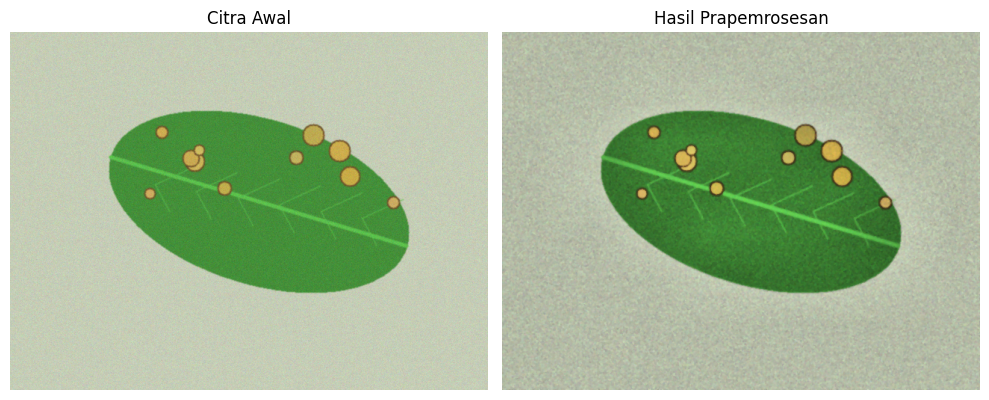

In [4]:
from src.praproses import praproses, PARAM_BAWAAN

# Baca salah satu citra daun teh
img = baca("data/sintetis/citra/teh_041.png")

# Jalankan prapemrosesan
hasil = praproses(img)

print("Ukuran citra awal:", img.shape)
print("Ukuran setelah prapemrosesan:", hasil.shape)
print("Tipe data:", hasil.dtype)
print("Parameter bawaan:", PARAM_BAWAAN)

# Tampilkan perbandingan
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Citra Awal")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB))
plt.title("Hasil Prapemrosesan")
plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
from src.praproses import simpan_param

PARAM = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0
}

simpan_param(PARAM)

print("Parameter berhasil disimpan!")
print(PARAM)

Parameter berhasil disimpan!
{'lebar': 640, 'gamma': 1.0, 'clahe_clip': 2.0, 'clahe_tile': 8, 'penapis': 'median', 'kernel': 3, 'sigma': 1.0, 'tajam_k': 0.0}


In [6]:
label = pd.read_csv("data/sintetis/label.csv")

print("Jumlah seluruh citra:", len(label))
print("\nKelas citra:")
print(label["kelas"].value_counts())

print("\nKondisi pencahayaan:")
print(label["kondisi_cahaya"].value_counts())

print("\nContoh data:")
display(label.head())

Jumlah seluruh citra: 60

Kelas citra:
kelas
sehat     20
ringan    20
berat     20
Name: count, dtype: int64

Kondisi pencahayaan:
kondisi_cahaya
normal            12
gelap             12
terang            12
kontras_rendah    12
bayangan          12
Name: count, dtype: int64

Contoh data:


,nama_file,kelas,kondisi_cahaya,persen_bercak
0,teh_001.png,sehat,normal,0.0
1,teh_002.png,sehat,gelap,0.0
2,teh_003.png,sehat,terang,0.0
3,teh_004.png,sehat,kontras_rendah,0.0
4,teh_005.png,sehat,bayangan,0.0


In [7]:
from src.praproses import praproses

KANAL = 2  # Kanal R pada citra BGR

data_hasil = []

# Ambil 40 citra yang memiliki bercak
data_bercak = label[label["kelas"] != "sehat"]

for _, baris in data_bercak.iterrows():
    nama = baris["nama_file"]

    # Baca citra dan mask
    img = baca(f"data/sintetis/citra/{nama}")
    mask_daun = cv2.imread(
        f"data/sintetis/mask_daun/{nama}", 0
    )
    mask_bercak = cv2.imread(
        f"data/sintetis/mask_bercak/{nama}", 0
    )

    # Citra sebelum prapemrosesan
    sebelum = img[:, :, KANAL]

    # Citra setelah prapemrosesan
    img_sesudah = praproses(img)
    sesudah = img_sesudah[:, :, KANAL]

    # Hitung kontras bercak
    kb_sebelum = kontras_bercak(
        sebelum, mask_daun, mask_bercak
    )
    kb_sesudah = kontras_bercak(
        sesudah, mask_daun, mask_bercak
    )

    data_hasil.append({
        "nama_file": nama,
        "kelas": baris["kelas"],
        "kondisi_cahaya": baris["kondisi_cahaya"],
        "KB_sebelum": kb_sebelum,
        "KB_sesudah": kb_sesudah
    })

df_hasil = pd.DataFrame(data_hasil)

print("Jumlah citra yang diuji:", len(df_hasil))
display(df_hasil.head(10))

Jumlah citra yang diuji: 40


,nama_file,kelas,kondisi_cahaya,KB_sebelum,KB_sesudah
0,teh_021.png,ringan,normal,6.709819,7.450064
1,teh_022.png,ringan,gelap,10.906986,15.564838
2,teh_023.png,ringan,terang,7.010088,4.903245
3,teh_024.png,ringan,kontras_rendah,2.047713,2.368991
4,teh_025.png,ringan,bayangan,6.776549,9.024846
5,teh_026.png,ringan,normal,9.045209,9.686281
6,teh_027.png,ringan,gelap,6.608970,10.393102
7,teh_028.png,ringan,terang,4.292466,3.303555
8,teh_029.png,ringan,kontras_rendah,2.477199,3.950818
9,teh_030.png,ringan,bayangan,3.782304,4.837425


In [8]:
ringkasan = df_hasil.groupby("kondisi_cahaya")[
    ["KB_sebelum", "KB_sesudah"]
].mean().reset_index()

ringkasan["Perubahan_KB"] = (
    ringkasan["KB_sesudah"] - ringkasan["KB_sebelum"]
)

print("Rata-rata kontras bercak berdasarkan kondisi pencahayaan:")
display(ringkasan.round(3))

# Simpan hasil pengujian
df_hasil.to_csv("hasil/b5_kb_40_citra.csv", index=False)
ringkasan.to_csv("hasil/b5_ringkasan_kb.csv", index=False)

print("Tabel berhasil disimpan.")

Rata-rata kontras bercak berdasarkan kondisi pencahayaan:


,kondisi_cahaya,KB_sebelum,KB_sesudah,Perubahan_KB
0,bayangan,5.218,8.318,3.100
1,gelap,8.683,14.858,6.174
2,kontras_rendah,3.499,4.466,0.967
3,normal,9.433,11.123,1.690
4,terang,6.427,5.799,-0.629


Tabel berhasil disimpan.


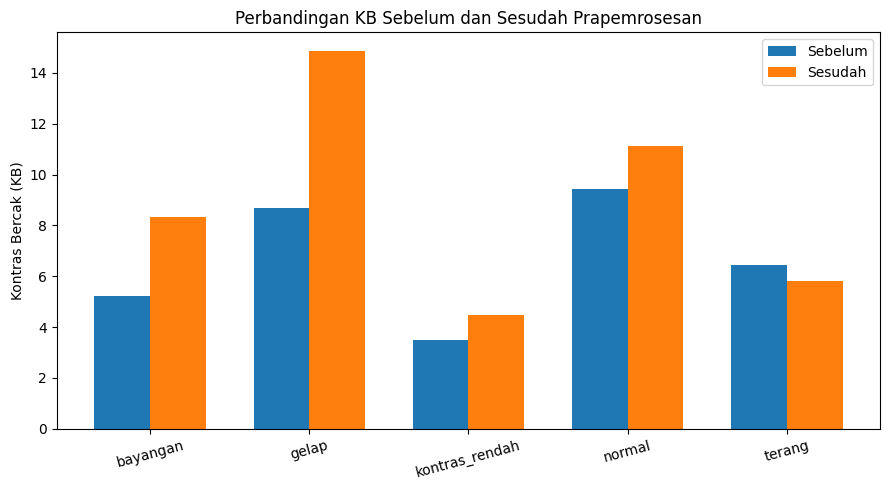

In [9]:
plt.figure(figsize=(9, 5))

x = np.arange(len(ringkasan))
lebar = 0.35

plt.bar(
    x - lebar/2,
    ringkasan["KB_sebelum"],
    lebar,
    label="Sebelum"
)

plt.bar(
    x + lebar/2,
    ringkasan["KB_sesudah"],
    lebar,
    label="Sesudah"
)

plt.xticks(x, ringkasan["kondisi_cahaya"], rotation=15)
plt.ylabel("Kontras Bercak (KB)")
plt.title("Perbandingan KB Sebelum dan Sesudah Prapemrosesan")
plt.legend()
plt.tight_layout()

plt.savefig("hasil/b5_perbandingan_kb.png", dpi=150)
plt.show()

In [10]:
data_sehat = label[label["kelas"] == "sehat"]

hasil_sehat = []

for _, baris in data_sehat.iterrows():
    nama = baris["nama_file"]

    # Baca citra dan mask daun
    img = baca(f"data/sintetis/citra/{nama}")
    mask_daun = cv2.imread(
        f"data/sintetis/mask_daun/{nama}", 0
    )

    # Kanal R sebelum dan sesudah prapemrosesan
    sebelum = img[:, :, 2]

    img_sesudah = praproses(img)
    sesudah = img_sesudah[:, :, 2]

    # Hitung simpangan baku pada area daun
    std_sebelum = sebelum[mask_daun > 0].std()
    std_sesudah = sesudah[mask_daun > 0].std()

    hasil_sehat.append({
        "nama_file": nama,
        "kondisi_cahaya": baris["kondisi_cahaya"],
        "std_sebelum": std_sebelum,
        "std_sesudah": std_sesudah
    })

df_sehat = pd.DataFrame(hasil_sehat)

print("Jumlah citra sehat yang diuji:", len(df_sehat))
display(df_sehat.head(10))

Jumlah citra sehat yang diuji: 20


,nama_file,kondisi_cahaya,std_sebelum,std_sesudah
0,teh_001.png,normal,15.057595,11.788215
1,teh_002.png,gelap,9.970527,6.564074
2,teh_003.png,terang,11.526921,12.680222
3,teh_004.png,kontras_rendah,14.216642,11.719453
4,teh_005.png,bayangan,10.409181,7.825229
5,teh_006.png,normal,9.507067,9.780485
6,teh_007.png,gelap,7.826195,5.063757
7,teh_008.png,terang,11.929144,14.550417
8,teh_009.png,kontras_rendah,9.355587,10.012625
9,teh_010.png,bayangan,12.936108,10.225882


In [11]:
ringkasan_sehat = df_sehat.groupby("kondisi_cahaya")[
    ["std_sebelum", "std_sesudah"]
].mean().reset_index()

ringkasan_sehat["Perubahan_std"] = (
    ringkasan_sehat["std_sesudah"]
    - ringkasan_sehat["std_sebelum"]
)

print("Rata-rata simpangan baku citra sehat:")
display(ringkasan_sehat.round(3))

# Simpan hasil
df_sehat.to_csv("hasil/b5_uji_20_citra_sehat.csv", index=False)
ringkasan_sehat.to_csv(
    "hasil/b5_ringkasan_citra_sehat.csv", index=False
)

print("Hasil pengujian citra sehat berhasil disimpan.")

Rata-rata simpangan baku citra sehat:


,kondisi_cahaya,std_sebelum,std_sesudah,Perubahan_std
0,bayangan,13.400,9.327,-4.073
1,gelap,10.837,6.726,-4.111
2,kontras_rendah,10.461,10.477,0.016
3,normal,11.467,10.120,-1.347
4,terang,11.053,12.668,1.614


Hasil pengujian citra sehat berhasil disimpan.


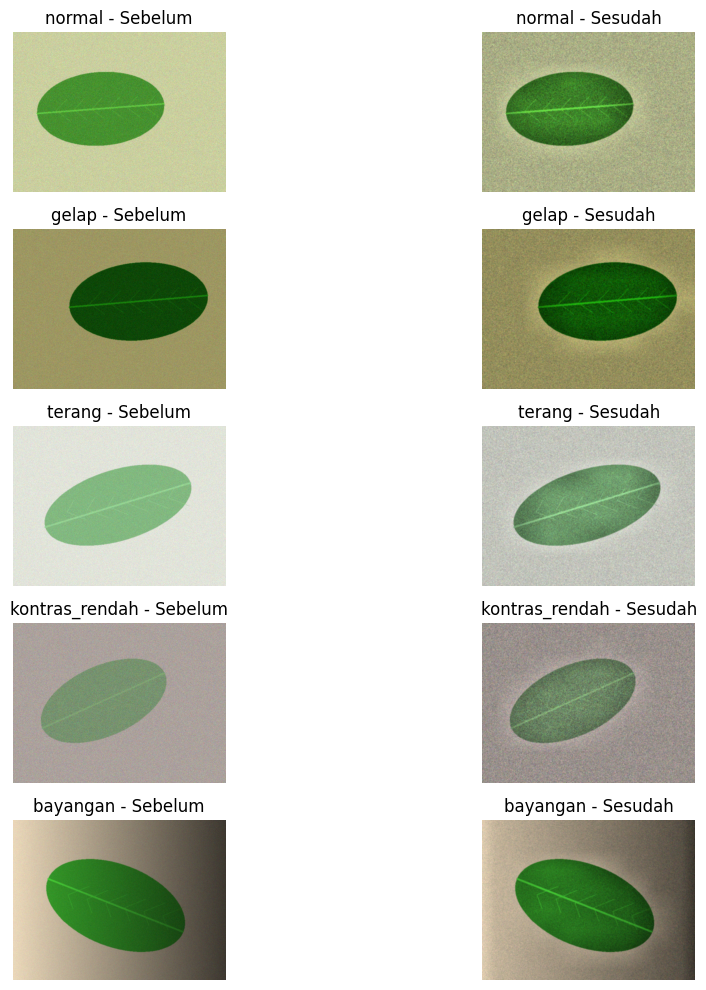

In [12]:
kondisi = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]

plt.figure(figsize=(12, 10))

for i, cahaya in enumerate(kondisi):
    baris = label[
        (label["kelas"] == "sehat") &
        (label["kondisi_cahaya"] == cahaya)
    ].iloc[0]

    nama = baris["nama_file"]
    img = baca(f"data/sintetis/citra/{nama}")
    hasil = praproses(img)

    plt.subplot(5, 2, 2*i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"{cahaya} - Sebelum")
    plt.axis("off")

    plt.subplot(5, 2, 2*i + 2)
    plt.imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB))
    plt.title(f"{cahaya} - Sesudah")
    plt.axis("off")

plt.tight_layout()
plt.savefig("hasil/b5_perbandingan_citra_sehat.png", dpi=150)
plt.show()

In [13]:
print("Kondisi dengan kenaikan simpangan baku terbesar:")
print(
    ringkasan_sehat.loc[
        ringkasan_sehat["Perubahan_std"].idxmax()
    ]
)

print("\nKondisi dengan penurunan simpangan baku terbesar:")
print(
    ringkasan_sehat.loc[
        ringkasan_sehat["Perubahan_std"].idxmin()
    ]
)


Kondisi dengan kenaikan simpangan baku terbesar:
kondisi_cahaya       terang
std_sebelum       11.053296
std_sesudah       12.667767
Perubahan_std      1.614471
Name: 4, dtype: object

Kondisi dengan penurunan simpangan baku terbesar:
kondisi_cahaya       gelap
std_sebelum       10.83715
std_sesudah       6.726411
Perubahan_std    -4.110738
Name: 1, dtype: object


In [15]:
tabel_parameter = pd.DataFrame([
    ["Resize", "640 piksel", "Menyesuaikan ukuran citra"],
    ["Gamma", "1.0", "Mempertahankan kecerahan awal"],
    ["CLAHE", "2.0", "Meningkatkan kontras lokal"],
    ["CLAHE Tile", "8 x 8", "Mengatur ukuran area CLAHE"],
    ["Penapis", "Median", "Mengurangi derau"],
    ["Kernel", "3 x 3", "Menjaga detail bercak"],
    ["Sigma", "1.0", "Parameter Gaussian"],
    ["Penajaman", "0.0", "Tidak menggunakan penajaman"]
], columns=["Tahapan", "Parameter Final", "Alasan Pemilihan"])

display(tabel_parameter)

,Tahapan,Parameter Final,Alasan Pemilihan
0,Resize,640 piksel,Menyesuaikan ukuran citra
1,Gamma,1.0,Mempertahankan kecerahan awal
2,CLAHE,2.0,Meningkatkan kontras lokal
3,CLAHE Tile,8 x 8,Mengatur ukuran area CLAHE
4,Penapis,Median,Mengurangi derau
5,Kernel,3 x 3,Menjaga detail bercak
6,Sigma,1.0,Parameter Gaussian
7,Penajaman,0.0,Tidak menggunakan penajaman


In [16]:
from graphviz import Digraph

dot = Digraph("Pipeline_SIMUTEH", format="png")
dot.attr(rankdir="TB", size="8,10")
dot.attr("node", shape="box", style="rounded,filled",
         fillcolor="lightyellow", fontname="Arial")

tahapan = [
    ("A", "AKUISISI CITRA\nFoto daun teh"),
    ("B", "PRAPEMROSESAN\nResize 640 px\nGamma 1.0\nCLAHE 2.0, Tile 8x8\nMedian 3x3"),
    ("C", "SEGMENTASI\nMemisahkan area daun dan bercak"),
    ("D", "EKSTRAKSI CIRI\nMenghitung fitur citra"),
    ("E", "KLASIFIKASI\nMenentukan kelas mutu"),
    ("F", "INTERPRETASI\nSehat, Bercak Ringan,\natau Bercak Berat")
]

for kode, label_tahap in tahapan:
    dot.node(kode, label_tahap)

for i in range(len(tahapan)-1):
    dot.edge(tahapan[i][0], tahapan[i+1][0])

dot.render("hasil/b5_pipeline_final", cleanup=True)
print("Diagram pipeline berhasil disimpan!")

Diagram pipeline berhasil disimpan!


In [17]:
import os

print("FILE HASIL P5:")
for nama in sorted(os.listdir("hasil")):
    if nama.startswith("b5_") or nama == "param_praproses.json":
        print("-", nama)

print("\nFILE MODUL:")
print(os.path.exists("src/praproses.py"))

FILE HASIL P5:
- b5_kb_40_citra.csv
- b5_perbandingan_citra_sehat.png
- b5_perbandingan_kb.png
- b5_pipeline_final.png
- b5_ringkasan_citra_sehat.csv
- b5_ringkasan_kb.csv
- b5_uji_20_citra_sehat.csv
- param_praproses.json

FILE MODUL:
True
